In [1]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [2]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 67.0 MB/s  0:00:00


In [3]:
!wget -c https://stringdb-downloads.org/download/protein.links.v12.0/511145.protein.links.v12.0.txt.gz

--2026-10-29 07:10:37--  https://stringdb-downloads.org/download/protein.links.v12.0/511145.protein.links.v12.0.txt.gz
Resolving stringdb-downloads.org (stringdb-downloads.org)... 49.12.123.75
Connecting to stringdb-downloads.org (stringdb-downloads.org)|49.12.123.75|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4959344 (4.7M) [application/octet-stream]
Saving to: ‘511145.protein.links.v12.0.txt.gz’

511145.protein.link 100%[===================>]   4.73M  4.14MB/s    in 1.1s    

2026-10-29 07:10:39 (4.14 MB/s) - ‘511145.protein.links.v12.0.txt.gz’ saved [4959344/4959344]



In [4]:
import gzip
import shutil

with gzip.open("511145.protein.links.v12.0.txt.gz", "rb") as f_in:
    with open("511145.protein.links.v12.0.txt", "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

print("Interaction file extracted successfully.")

Interaction file extracted successfully.


In [5]:
import pandas as pd

df = pd.read_csv(
    "511145.protein.links.v12.0.txt",
    sep=r"\s+")
df["protein1"] = df["protein1"].str.replace("511145.", "", regex=False)
df["protein2"] = df["protein2"].str.replace("511145.", "", regex=False)
df = df[df["combined_score"] >= 400]

df["label"] = (df["combined_score"] >= 700).astype(int)

In [6]:
proteins = list(set(df["protein1"]).union(set(df["protein2"])))

existing_edges = {
    tuple(sorted((a, b)))
    for a, b in zip(df["protein1"], df["protein2"])
}

pos_df = df[df["label"] == 1][["protein1", "protein2", "label"]]

negative_pairs = set()

while len(negative_pairs) < len(pos_df):

    a, b = random.sample(proteins, 2)

    pair = tuple(sorted((a, b)))

    if pair in existing_edges:
        continue

    negative_pairs.add(pair)

neg_df = pd.DataFrame(
    list(negative_pairs),
    columns=["protein1", "protein2"]
)

neg_df["label"] = 0

final_df = pd.concat(
    [pos_df, neg_df],
    ignore_index=True
).sample(frac=1, random_state=SEED).reset_index(drop=True)

In [7]:
final_df[["protein1","protein2"]] = (
    final_df.apply(
        lambda x: sorted([x["protein1"], x["protein2"]]),
        axis=1,
        result_type="expand"
    )
)

final_df = final_df.drop_duplicates(
    subset=["protein1","protein2"]
).reset_index(drop=True)

In [8]:
with open("511145.protein.links.v12.0.txt", "r") as f:
    for i in range(5):
        print(f.readline())

protein1 protein2 combined_score

511145.b0001 511145.b1715 520

511145.b0001 511145.b3783 208

511145.b0001 511145.b2310 275

511145.b0001 511145.b0005 335



In [9]:
!wget -c https://stringdb-downloads.org/download/protein.sequences.v12.0/511145.protein.sequences.v12.0.fa.gz

--2026-10-29 07:10:51--  https://stringdb-downloads.org/download/protein.sequences.v12.0/511145.protein.sequences.v12.0.fa.gz
Resolving stringdb-downloads.org (stringdb-downloads.org)... 49.12.123.75
Connecting to stringdb-downloads.org (stringdb-downloads.org)|49.12.123.75|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 802860 (784K) [application/octet-stream]
Saving to: ‘511145.protein.sequences.v12.0.fa.gz’

511145.protein.sequ 100%[===================>] 784.04K  1.17MB/s    in 0.7s    

2026-10-29 07:10:55 (1.17 MB/s) - ‘511145.protein.sequences.v12.0.fa.gz’ saved [802860/802860]



In [10]:
import gzip
import shutil

with gzip.open("511145.protein.sequences.v12.0.fa.gz", "rb") as f_in:
    with open("511145.protein.sequences.v12.0.fa", "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

In [11]:
from Bio import SeqIO

protein_sequences = {}

for record in SeqIO.parse("511145.protein.sequences.v12.0.fa", "fasta"):
    protein_sequences[record.id.replace("511145.", "")] = str(record.seq)

proteins = list(protein_sequences.keys())

unique_proteins = pd.DataFrame({
    "protein": proteins,
    "sequence": [protein_sequences[p] for p in proteins]
})

In [12]:
unique_proteins.to_csv(
    "ecoli_unique_proteins.csv",
    index=False
)

In [13]:
!pip install fair-esm

In [14]:

import esm
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model, alphabet = (
    esm.pretrained.esm2_t6_8M_UR50D()
)

model = model.to(device)

model.eval()

batch_converter = (
    alphabet.get_batch_converter()
)

print(device)

Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t6_8M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t6_8M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D-contact-regression.pt
cuda


In [15]:
import numpy as np

@torch.no_grad()
def get_embedding(sequence):

    sequence = sequence[:1022]

    data = [
        (
            "protein",
            sequence
        )
    ]

    _, _, tokens = (
        batch_converter(data)
    )

    tokens = tokens.to(device)

    results = model(
        tokens,
        repr_layers=[6],
        return_contacts=False
    )

    token_embeddings = (
        results["representations"][6]
    )

    embedding = (
        token_embeddings[0,1:-1]
        .mean(0)
    )

    return embedding.cpu().numpy()

In [16]:
from tqdm import tqdm

protein_embeddings = {}

for _, row in tqdm(
    unique_proteins.iterrows(),
    total=len(unique_proteins)
):

    protein_id = row["protein"]

    sequence = row["sequence"]

    protein_embeddings[
        protein_id
    ] = get_embedding(
        sequence
    )

print(
    len(protein_embeddings)
)

100%|██████████| 4140/4140 [00:53<00:00, 77.24it/s] 

4140


In [17]:
print(len(protein_embeddings))

4140


In [18]:

from sklearn.model_selection import train_test_split

# 1. Get all unique proteins appearing in the interaction dataset
all_pair_proteins = sorted(
    set(final_df["protein1"]) | set(final_df["protein2"])
)

# 2. Split proteins: 80% train, 10% validation, 10% test
train_proteins, temp_proteins = train_test_split(
    all_pair_proteins,
    test_size=0.20,
    random_state=SEED
)

valid_proteins, test_proteins = train_test_split(
    temp_proteins,
    test_size=0.50,
    random_state=SEED
)

train_proteins = set(train_proteins)
valid_proteins = set(valid_proteins)
test_proteins = set(test_proteins)

# 3. Keep only pairs whose BOTH proteins belong to the same split
train_df = final_df[
    final_df["protein1"].isin(train_proteins) &
    final_df["protein2"].isin(train_proteins)
].copy().reset_index(drop=True)

valid_df = final_df[
    final_df["protein1"].isin(valid_proteins) &
    final_df["protein2"].isin(valid_proteins)
].copy().reset_index(drop=True)

test_df = final_df[
    final_df["protein1"].isin(test_proteins) &
    final_df["protein2"].isin(test_proteins)
].copy().reset_index(drop=True)

# 4. Verify that protein groups do not overlap
print("Protein-disjoint split verification")
print("=" * 45)

print("Training proteins  :", len(train_proteins))
print("Validation proteins:", len(valid_proteins))
print("Test proteins      :", len(test_proteins))

print("\nRetained interaction pairs")
print("Training pairs  :", len(train_df))
print("Validation pairs:", len(valid_df))
print("Test pairs      :", len(test_df))

print("\nProtein overlap checks")
print("Train ∩ Validation:", len(train_proteins & valid_proteins))
print("Train ∩ Test      :", len(train_proteins & test_proteins))
print("Validation ∩ Test :", len(valid_proteins & test_proteins))

print("\nPair label distributions")
print("Training:\n", train_df["label"].value_counts().sort_index())
print("Validation:\n", valid_df["label"].value_counts().sort_index())
print("Test:\n", test_df["label"].value_counts().sort_index())

print("\nExcluded cross-group pairs:",
      len(final_df) - len(train_df) - len(valid_df) - len(test_df))


Protein-disjoint split verification
Training proteins  : 3312
Validation proteins: 414
Test proteins      : 414

Retained interaction pairs
Training pairs  : 61630
Validation pairs: 1013
Test pairs      : 875

Protein overlap checks
Train ∩ Validation: 0
Train ∩ Test      : 0
Validation ∩ Test : 0

Pair label distributions
Training:
 label
0    41180
1    20450
Name: count, dtype: int64
Validation:
 label
0    662
1    351
Name: count, dtype: int64
Test:
 label
0    561
1    314
Name: count, dtype: int64

Excluded cross-group pairs: 33214


In [19]:
def pair_set(df):
    return set(
        tuple(sorted((a,b)))
        for a,b in zip(df.protein1, df.protein2)
    )

train_pairs = pair_set(train_df)
valid_pairs = pair_set(valid_df)
test_pairs = pair_set(test_df)

print("Train ∩ Valid =", len(train_pairs & valid_pairs))
print("Train ∩ Test  =", len(train_pairs & test_pairs))
print("Valid ∩ Test  =", len(valid_pairs & test_pairs))

Train ∩ Valid = 0
Train ∩ Test  = 0
Valid ∩ Test  = 0


In [20]:
# train_df = train_df[
#     train_df["protein1"].isin(valid_proteins) &
#     train_df["protein2"].isin(valid_proteins)
# ].reset_index(drop=True)

# valid_df = valid_df[
#     valid_df["protein1"].isin(valid_proteins) &
#     valid_df["protein2"].isin(valid_proteins)
# ].reset_index(drop=True)

# test_df = test_df[
#     test_df["protein1"].isin(valid_proteins) &
#     test_df["protein2"].isin(valid_proteins)
# ].reset_index(drop=True)

In [21]:
final_df.to_csv(
    "ecoli_full_pd.csv",
    index=False
)

train_df.to_csv(
    "train_ecoli_pd.csv",
    index=False
)

valid_df.to_csv(
    "valid_ecoli_pd.csv",
    index=False
)

test_df.to_csv(
    "test_ecoli_pd.csv",
    index=False
)

In [22]:
import numpy as np
import torch

proteins = list(
    protein_embeddings.keys()
)

protein_to_idx = {
    p:i
    for i,p in enumerate(proteins)
}

X = np.array(
    [protein_embeddings[p]
     for p in proteins],
    dtype=np.float32
)

x = torch.tensor(X)

print(x.shape)

torch.Size([4140, 320])


In [23]:
positive_train = train_df[
    train_df["label"] == 1
]
print(positive_train.shape)

(20450, 3)


In [24]:
from collections import defaultdict

neighbors = defaultdict(set)

for _, row in positive_train.iterrows():

    p1 = row["protein1"]
    p2 = row["protein2"]

    neighbors[p1].add(p2)
    neighbors[p2].add(p1)

print(len(neighbors))

3154


In [25]:
hyperedges = []

for protein in neighbors:

    members = set()

    members.add(protein)

    members.update(
        neighbors[protein]
    )

    hyperedges.append(
        list(members)
    )

print(len(hyperedges))

3154


In [26]:

node_ids = []
edge_ids = []

for edge_id, members in enumerate(hyperedges):

    for protein in members:

        if protein in protein_to_idx and protein in train_proteins:

            node_ids.append(
                protein_to_idx[protein]
            )

            edge_ids.append(
                edge_id
            )

hyperedge_index = torch.tensor(
    [node_ids, edge_ids],
    dtype=torch.long
)

print(hyperedge_index.shape)


torch.Size([2, 44054])


In [27]:
!pip install torch-geometric
!pip install tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.0 MB/s  0:00:00


In [28]:

from torch_geometric.data import Data

graph = Data(
    x=x,
    hyperedge_index=hyperedge_index
)

print(graph)


Data(x=[4140, 320], hyperedge_index=[2, 44054])


In [29]:

print("Graph nodes:", graph.x.shape[0])
print("Embedding dimensions:", graph.x.shape[1])
print("Hyperedge index shape:", graph.hyperedge_index.shape)

used_node_indices = graph.hyperedge_index[0].unique().tolist()
used_proteins = {proteins[i] for i in used_node_indices}

print("Proteins connected to training hyperedges:", len(used_proteins))
print(
    "Non-training proteins in hyperedges:",
    len(used_proteins - train_proteins)
)


Graph nodes: 4140
Embedding dimensions: 320
Hyperedge index shape: torch.Size([2, 44054])
Proteins connected to training hyperedges: 3154
Non-training proteins in hyperedges: 0


In [30]:
graph = graph.to(device)

print(graph.x.device)
print(graph.hyperedge_index.device)

cuda:0
cuda:0


In [31]:
train_pairs = []

for _, row in train_df.iterrows():

    train_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

valid_pairs = []

for _, row in valid_df.iterrows():

    valid_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

test_pairs = []

for _, row in test_df.iterrows():

    test_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

print(len(train_pairs))
print(len(valid_pairs))
print(len(test_pairs))

61630
1013
875


In [32]:
from torch.utils.data import Dataset

class PPIDataset(Dataset):

    def __init__(self,data):

        self.data=data

    def __len__(self):

        return len(self.data)

    def __getitem__(self,idx):

        p1,p2,y=self.data[idx]

        return (

            torch.tensor(p1),

            torch.tensor(p2),

            torch.tensor(y,dtype=torch.float32)

        )

In [33]:
from torch.utils.data import DataLoader

train_dataset = PPIDataset(
    train_pairs
)

valid_dataset = PPIDataset(
    valid_pairs
)

test_dataset = PPIDataset(
    test_pairs
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

In [34]:
from torch_geometric.nn import HypergraphConv
import torch.nn as nn
import torch.nn.functional as F

class HGNNEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.protein_encoder = nn.Sequential(

            nn.Linear(320, 512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 320)

        )

        self.h1 = HypergraphConv(
            320,
            512
        )

        self.h2 = HypergraphConv(
            512,
            256
        )

        self.h3 = HypergraphConv(
            256,
            128
        )

    def forward(
        self,
        x,
        hyperedge_index
    ):

        residual = x

        x = self.protein_encoder(x)

        x = x + residual

        x = self.h1(
            x,
            hyperedge_index
        )

        x = F.relu(x)

        x = self.h2(
            x,
            hyperedge_index
        )

        x = F.relu(x)

        x = self.h3(
            x,
            hyperedge_index
        )

        return x

In [35]:
class TrainableHGNNPPI(nn.Module):

    def __init__(self):

        super().__init__()

        self.hgnn = HGNNEncoder()

        self.input_proj = nn.Linear(
            448,
            256
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=256,
            num_heads=8,
            batch_first=True
        )



        self.classifier = nn.Sequential(

            nn.Linear(
                1024,
                512
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                512,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                128,
                1
            )
        )

    def forward(
        self,
        p1_idx,
        p2_idx,
        graph_x,
        hyperedge_index
    ):

        hgnn_emb = self.hgnn(
            graph_x,
            hyperedge_index
        )

        final_emb = torch.cat(
            [graph_x, hgnn_emb],
            dim=1
        )

        p1 = final_emb[p1_idx]
        p2 = final_emb[p2_idx]

        p1 = self.input_proj(p1)
        p2 = self.input_proj(p2)

        attn_out, _ = self.attention(
            p1.unsqueeze(1),
            p2.unsqueeze(1),
            p2.unsqueeze(1)
        )

        attn_out = attn_out.squeeze(1)



        features = torch.cat([
            p1,
            p2,
            torch.abs(p1-p2),
            attn_out
        ], dim=1)

        return self.classifier(
            features
        ).squeeze()

In [36]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = TrainableHGNNPPI().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print(device)

cuda


In [37]:
!pip install thop

In [38]:
from sklearn.metrics import roc_auc_score
from tqdm import tqdm
import torch

best_auc = 0
counter = 0

EPOCHS = 20

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for p1, p2, y in tqdm(train_loader):

        p1 = p1.to(device)
        p2 = p2.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        loss = criterion(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}",
        total_loss / len(train_loader)
    )

    model.eval()

    valid_probs = []
    valid_labels = []

    with torch.no_grad():

        for p1, p2, y in valid_loader:

            p1 = p1.to(device)
            p2 = p2.to(device)

            logits = model(
                p1,
                p2,
                graph.x,
                graph.hyperedge_index
            )

            prob = torch.sigmoid(
                logits
            )

            valid_probs.extend(
                prob.detach().cpu().reshape(-1).numpy()
            )

            valid_labels.extend(
              y.detach().cpu().reshape(-1).numpy()
            )

    valid_auc = roc_auc_score(
        valid_labels,
        valid_probs
    )

    print(
        "Validation AUC:",
        valid_auc
    )

    if valid_auc > best_auc:

        best_auc = valid_auc

        torch.save(
    model.state_dict(),
    "best_model_ecoli.pth"
)

        counter = 0

        print(
            "New best model saved"
        )

    else:

        counter += 1

        if counter >= 5:

            print(
                "Early stopping"
            )

            break

print(
    "Best Validation AUC:",
    best_auc
)


100%|██████████| 482/482 [00:25<00:00, 18.78it/s]


Epoch 1 0.253893751635591
Validation AUC: 0.7778337249636343
New best model saved


100%|██████████| 482/482 [00:12<00:00, 40.12it/s]


Epoch 2 0.16669115228617093
Validation AUC: 0.7747695406305678


100%|██████████| 482/482 [00:12<00:00, 39.88it/s]


Epoch 3 0.1498009019697479
Validation AUC: 0.7745285373684165


... (2 outputs left out)

100%|██████████| 482/482 [00:12<00:00, 37.17it/s]


Epoch 5 0.12542388864108883
Validation AUC: 0.7414207142303818


100%|██████████| 482/482 [00:12<00:00, 39.42it/s]

Epoch 6 0.1165857907941109
Validation AUC: 0.740288859624207
Early stopping
Best Validation AUC: 0.7778337249636343


In [39]:
model.load_state_dict(
    torch.load("best_model_ecoli.pth", map_location=device)
)
model.eval()

print("Best model loaded successfully.")

Best model loaded successfully.


In [40]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve
)
import numpy as np
import torch

model.eval()

# ---------------------------------
# 1. Get validation probabilities
# ---------------------------------
val_probs = []
val_labels = []

with torch.no_grad():
    for p1, p2, y in valid_loader:
        p1 = p1.to(device)
        p2 = p2.to(device)

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        prob = torch.sigmoid(logits)

        val_probs.extend(prob.cpu().reshape(-1).numpy())
        val_labels.extend(y.cpu().reshape(-1).numpy())

val_probs = np.array(val_probs)
val_labels = np.array(val_labels)

# ---------------------------------
# 2. Select threshold using validation F1
# ---------------------------------
precision_vals, recall_vals, thresholds = precision_recall_curve(
    val_labels,
    val_probs
)

f1_vals = (
    2 * precision_vals[:-1] * recall_vals[:-1]
    / (precision_vals[:-1] + recall_vals[:-1] + 1e-12)
)

best_idx = np.argmax(f1_vals)
best_threshold = thresholds[best_idx]

print("Best validation threshold:", best_threshold)
print("Best validation F1:", f1_vals[best_idx])

# ---------------------------------
# 3. Evaluate test set once
# ---------------------------------
test_probs = []
test_labels = []

with torch.no_grad():
    for p1, p2, y in test_loader:
        p1 = p1.to(device)
        p2 = p2.to(device)

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        prob = torch.sigmoid(logits)

        test_probs.extend(prob.cpu().reshape(-1).numpy())
        test_labels.extend(y.cpu().reshape(-1).numpy())

test_probs = np.array(test_probs)
test_labels = np.array(test_labels)

test_preds = (test_probs >= best_threshold).astype(int)

print("\nFINAL TEST RESULTS")
print("Threshold :", best_threshold)
print("Accuracy  :", accuracy_score(test_labels, test_preds))
print("AUC       :", roc_auc_score(test_labels, test_probs))
print("AUPR      :", average_precision_score(test_labels, test_probs))
print("F1-score  :", f1_score(test_labels, test_preds, zero_division=0))
print("Precision :", precision_score(test_labels, test_preds, zero_division=0))
print("Recall    :", recall_score(test_labels, test_preds, zero_division=0))
print("MCC       :", matthews_corrcoef(test_labels, test_preds))
print("Confusion matrix:\n", confusion_matrix(test_labels, test_preds))

Best validation threshold: 0.10365254
Best validation F1: 0.621438263228809

FINAL TEST RESULTS
Threshold : 0.10365254
Accuracy  : 0.7257142857142858
AUC       : 0.7577801242094985
AUPR      : 0.6863470632433671
F1-score  : 0.6091205211726385
Precision : 0.6233333333333333
Recall    : 0.5955414012738853
MCC       : 0.39826769819501473
Confusion matrix:
 [[448 113]
 [127 187]]


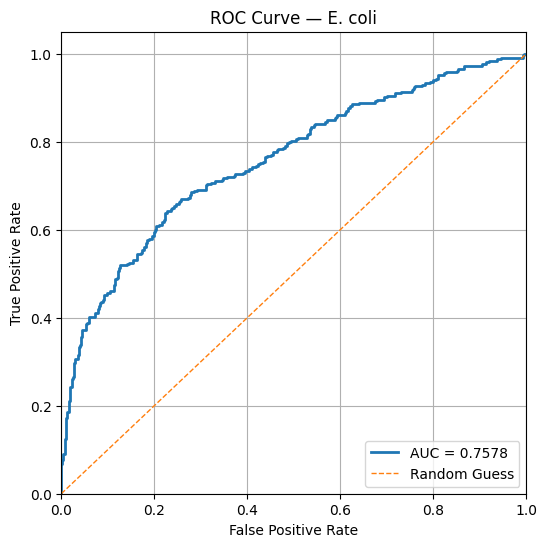

Test ROC-AUC: 0.7578


In [43]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Use the actual test labels and predicted probabilities
labels = test_labels
probs = test_probs

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(labels, probs)
auc = roc_auc_score(labels, probs)

# Plot ROC curve
plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Random Guess"
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — E. coli")

plt.legend(loc="lower right")
plt.grid(True)

plt.savefig(
    "ROC_Curve_ecoli.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Test ROC-AUC: {auc:.4f}")